In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from google.colab import files
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/cars_features.csv')
X = df.drop(columns=['price'])
y = df['price']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
num_cols = ['model_year', 'milage', 'horsepower', 'engine_size']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [ ]:
print(X_train.shape, X_test.shape)

(3184, 20) (797, 20)


In [ ]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)

In [ ]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [ ]:
mean_absolute_error(y_test, pred_lr)

16550.57086592108

In [ ]:
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

In [ ]:
results = pd.DataFrame(
    [evaluate(y_test, pred_lr), evaluate(y_test, pred_dt), evaluate(y_test, pred_rf)],
    columns=['MAE', 'RMSE', 'R2'],
    index=['Linear Regression', 'Decision Tree', 'Random Forest']
)
results.round(3)

,MAE,RMSE,R2
Linear Regression,16550.571,29025.011,0.444
Decision Tree,12723.977,28116.457,0.478
Random Forest,9488.819,19580.312,0.747


In [ ]:
pd.DataFrame({
    'train_R2': [
        r2_score(y_train, lr.predict(X_train_scaled)),
        r2_score(y_train, dt.predict(X_train)),
        r2_score(y_train, rf.predict(X_train))
    ],
    'test_R2': [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_dt),
        r2_score(y_test, pred_rf)
    ]
}, index=['Linear Regression', 'Decision Tree', 'Random Forest']).round(3)

,train_R2,test_R2
Linear Regression,0.432,0.444
Decision Tree,1.000,0.478
Random Forest,0.968,0.747


<div dir="ltr">

### Model Comparison

All three models were trained on the same training data and evaluated on the same 797 test cars. MAE and RMSE are in USD.

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 16,551 | 29,025 | 0.444 |
| Decision Tree | 12,724 | 28,116 | 0.478 |
| Random Forest | 9,489 | 19,580 | 0.747 |

**Which model has the lowest MAE?**

Random Forest, with an MAE of about 9,489 USD, compared with 12,724 USD for the Decision Tree and 16,551 USD for Linear Regression.

**Which model has the highest R²?**

Random Forest, with an R² of 0.747. The Decision Tree reached 0.478 and Linear Regression 0.444.

**Which model is the best, and why?**

Random Forest is the best model. It has the lowest MAE and RMSE and the highest R². Its MAE is about 24% of the average test price (about 39,900 USD), compared with about 41% for Linear Regression. The Decision Tree reached an R² of 1.000 on the training data but only 0.478 on the test data, which shows that it memorized the training data instead of learning general patterns. Random Forest also fits the training data better than the test data (0.968 compared with 0.747), but averaging many trees makes its test performance much better and more stable. Linear Regression has a similar R² on training and test data (0.432 and 0.444), so it does not memorize, but it is too simple to capture the nonlinear relationships between the features and the price. Note that these results come from a single train/test split, so small differences (for example, between Linear Regression and the Decision Tree in R²) should not be over-interpreted. The advantage of Random Forest is large.

**Did all models need feature scaling?**

No. Linear Regression was trained on scaled features, which makes its coefficients comparable and is important for regularized or gradient-based models, although the predictions of plain least-squares regression do not change with scaling. Decision Tree and Random Forest split the data using thresholds on one feature at a time, so only the order of the values matters and scaling has no effect on them. For this reason, the two tree-based models were trained on the original unscaled data.

</div>

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.round(4)

,0
milage,0.4247
engine_size,0.1775
horsepower,0.1537
model_year,0.0854
brand_encoded,0.0726
engine_type_encoded,0.0604
clean_title_encoded,0.0064
transmission_clean_Manual,0.0033
transmission_clean_Automatic,0.0031
fuel_type_Diesel,0.0027


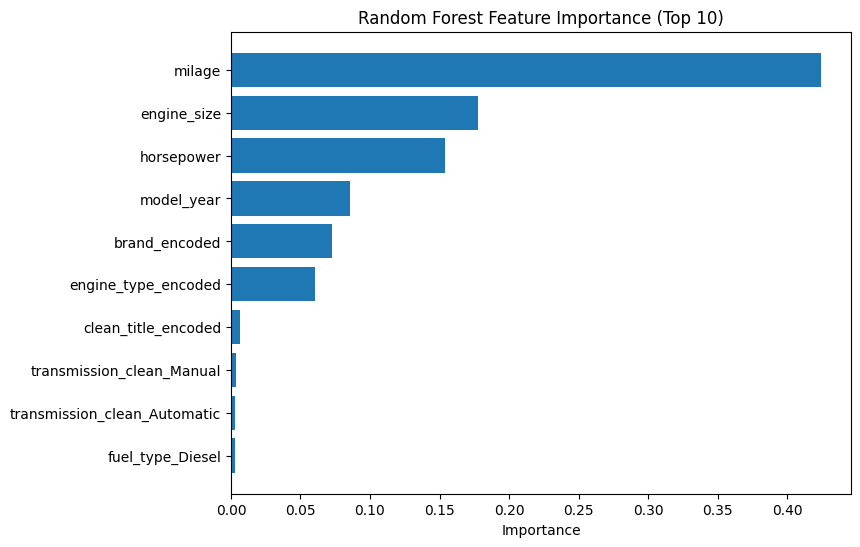

In [ ]:
top10 = importances.head(10).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(top10.index, top10.values)
plt.xlabel('Importance')
plt.title('Random Forest Feature Importance (Top 10)')
plt.show()

<div dir="ltr">

### Feature Importance in the Random Forest

The feature importance chart and table show that the top six features account for about 97% of the total importance, while the one-hot columns for fuel type and transmission and the accident column are almost irrelevant. The three most important features are:

1. **Mileage (importance about 0.42):** Mileage reflects the wear of the car, and buyers pay less for cars with more miles. The drop in price with mileage is nonlinear and steep at first, and a Random Forest can capture this curved relationship.
2. **Engine size (importance about 0.18):** Larger engines are usually used in bigger vehicles such as SUVs and trucks, and in luxury and sports models, which have higher prices.
3. **Horsepower (importance about 0.15):** Horsepower indicates the performance class of the car, and sports and luxury cars have much higher power and prices.

Some points should be kept in mind when interpreting these results. Feature importance only shows how much each feature contributed to reducing the error of the trees. It does not show the direction of the effect or a causal relationship. Correlated features, such as horsepower and engine size, and mileage and model year, share importance between them, so the lower rank of model year does not mean that it is unimportant. Brand, encoded with label encoding, has a notable share in this model, unlike in Linear Regression, because trees can split the brand codes separately. The fact that engine size ranks higher than horsepower may be caused by a larger share of horsepower values being filled with the median and by the correlation between the two features, but this is only a hypothesis.

</div>

In [ ]:
os.makedirs('models', exist_ok=True)
joblib.dump(rf, 'models/best_model.pkl', compress=3)

['models/best_model.pkl']

In [ ]:
os.path.getsize('models/best_model.pkl') / (1024 * 1024)

5.402751922607422

In [ ]:
loaded = joblib.load('models/best_model.pkl')
np.allclose(loaded.predict(X_test), pred_rf)

True

In [ ]:
files.download('models/best_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="ltr">

### Saving the Best Model

The best model, the Random Forest, was saved as `best_model.pkl` in the `models` folder. It was then loaded again to check that it produces identical predictions.

**Why is saving a model important in machine learning projects?**

A trained model exists only in memory and is lost when the notebook is closed or the session ends. Training it again takes time and resources, and the result may differ slightly. A saved model can be loaded without retraining, used to predict the prices of new cars, used to reproduce results, shared with teammates, and deployed in a real application or service. Different versions of a model can also be saved and compared.

Two points are important for correct use. New data must have exactly the same 20 columns in the same order as the training data. Also, pickle files should only be loaded from trusted sources, because loading them can execute code.

</div>